# CardioSafe AI - Notebook 08: prescription pipeline (image -> OCR -> drug names -> ingredients)

What this builds: `cardiosafe_rx.py` (line parser, OCR wrappers, synthetic-prescription generator) and installs medication module v2.1.

**How it is evaluated (honest scope):** we cannot use real patient prescriptions, so we generate **synthetic printed prescriptions** with known ground truth (brand + generic names, strengths, frequencies, header and advice lines) at three degradation levels (clean / rotated+noisy / low-resolution+heavy noise) and compare OCR engines on **drug-level precision and recall**. A medication counts only if its resolved ingredient set equals the prescribed one. Unrecognised names count as misses, never as guesses. **Handwritten prescriptions are not covered** and printed-font results will be optimistic; this goes in the limitations section.

Runtime: CPU is fine (about 10 to 20 minutes with EasyOCR, about 5 without). Needs the Drive folder from earlier notebooks.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
WORK = '/content/drive/MyDrive/CardioSafe'; KB = WORK + '/kb'
sys.path.insert(0, WORK)
!apt-get -qq install -y tesseract-ocr > /dev/null 2>&1
!pip -q install pytesseract rapidfuzz > /dev/null 2>&1
USE_EASYOCR = True
if USE_EASYOCR:
    !pip -q install easyocr > /dev/null 2>&1
import pytesseract; print('tesseract', pytesseract.get_tesseract_version())

Mounted at /content/drive
tesseract 5.3.4


In [ ]:
%%writefile /content/drive/MyDrive/CardioSafe/cardiosafe_kb.py
"""CardioSafe drug knowledge base.

- RxNorm: free-text drug name -> RxCUI -> ingredient names (https://rxnav.nlm.nih.gov/REST)
- openFDA drug labels: retrieves label sentences about QT prolongation / bradycardia / AV block, with section and citation
- DDInter: drug-drug interaction severity from the user's downloaded CSV files (CC BY-NC-SA 4.0, non-commercial use)
- CredibleMeds (optional): the user's own downloaded list, used locally for evaluation only; never redistributed

Nothing here invents medical claims: every flag carries the label sentence or table row it came from.
"""
import os, re, json, time, glob
import numpy as np
import pandas as pd

RXNAV = 'https://rxnav.nlm.nih.gov/REST'
FDA_LABEL = 'https://api.fda.gov/drug/label.json'
UA = {'User-Agent': 'CardioSafe-AI-course-project'}
STATS = {'requests': 0, 'errors': 0}


# ------------------------------------------------------------------ cache + http
class JsonCache:
    def __init__(self, path):
        self.path, self.d, self.dirty = path, {}, 0
        if path and os.path.exists(path):
            try:
                self.d = json.load(open(path))
            except Exception:
                self.d = {}

    def has(self, k): return k in self.d
    def get(self, k): return self.d.get(k)

    def set(self, k, v):
        self.d[k] = v
        self.dirty += 1
        if self.dirty % 20 == 0:
            self.save()

    def save(self):
        if self.path:
            tmp = self.path + '.tmp'
            json.dump(self.d, open(tmp, 'w'))
            os.replace(tmp, self.path)
        self.dirty = 0


def http_get(url, params=None, retries=3, pause=0.3, timeout=30):
    """GET -> parsed JSON; {'_status': 404/400} for those codes; None on network failure."""
    import requests
    for a in range(retries):
        try:
            r = requests.get(url, params=params, headers=UA, timeout=timeout)
            STATS['requests'] += 1
            if r.status_code in (400, 404):
                return {'_status': r.status_code}
            if r.status_code == 429:
                time.sleep(3 * (a + 1)); continue
            if r.status_code >= 400:
                STATS['errors'] += 1; time.sleep(1 + a); continue
            time.sleep(pause)
            return r.json()
        except Exception:
            STATS['errors'] += 1
            time.sleep(1 + a)
    return None


# ------------------------------------------------------------------- names
SALTS = (r'\b(?:hydrochloride|hcl|sodium|potassium|calcium|sulfate|sulphate|mesylate|maleate|tartrate|besylate|succinate|'
         r'fumarate|phosphate|acetate|citrate|bromide|nitrate|dihydrate|monohydrate|hydrobromide|magnesium|disodium|axetil)\b')


# International non-proprietary names vs the US names used by RxNorm / FDA labels / DDInter, so all sources agree on one name
SYNONYMS = {'paracetamol': 'acetaminophen', 'salbutamol': 'albuterol', 'adrenaline': 'epinephrine', 'noradrenaline': 'norepinephrine',
            'frusemide': 'furosemide', 'glibenclamide': 'glyburide', 'rifampicin': 'rifampin', 'lignocaine': 'lidocaine',
            'acetylsalicylic acid': 'aspirin', 'amoxycillin': 'amoxicillin', 'clavulanic acid': 'clavulanate',
            'clavulanate potassium': 'clavulanate', 'thyroxine': 'levothyroxine'}


def canon(name):
    """Canonical lower-case ingredient name: no salts, parentheses or punctuation; INN synonyms mapped to the US name."""
    s = str(name).lower()
    s = re.sub(r'\(.*?\)', ' ', s)
    s = re.sub(SALTS, ' ', s)
    s = re.sub(r'[^a-z0-9+/\- ]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return SYNONYMS.get(s, s)


# ------------------------------------------------------------------- RxNorm
def rx_approx(term, cache, n=5, option=0):
    """RxNorm approximate match. option=1 restricts to active concepts (retired concepts have no properties)."""
    key = f'approx|{option}|{term.lower().strip()}'
    if cache.has(key):
        return cache.get(key)
    js = http_get(f'{RXNAV}/approximateTerm.json', {'term': term, 'maxEntries': n, 'option': option})
    if js is None:
        return None
    out = []
    for c in (js.get('approximateGroup') or {}).get('candidate', []) or []:
        out.append({'rxcui': c.get('rxcui'), 'score': float(c.get('score') or 0), 'rank': int(c.get('rank') or 0),
                    'name': c.get('name'), 'source': c.get('source')})
    cache.set(key, out)
    return out


def rx_drugs(term, cache):
    """RxNorm getDrugs: clinical/branded drug concepts for a name (works well for brand names)."""
    key = f'drugs|{term.lower().strip()}'
    if cache.has(key):
        return cache.get(key)
    js = http_get(f'{RXNAV}/drugs.json', {'name': term})
    if js is None:
        return None
    out = []
    for g in (js.get('drugGroup') or {}).get('conceptGroup', []) or []:
        for c in g.get('conceptProperties', []) or []:
            out.append({'rxcui': c.get('rxcui'), 'name': c.get('name'), 'tty': c.get('tty')})
    out = out[:8]
    cache.set(key, out)
    return out


def rx_props(rxcui, cache):
    key = f'props|{rxcui}'
    if cache.has(key):
        return cache.get(key)
    js = http_get(f'{RXNAV}/rxcui/{rxcui}/properties.json')
    if js is None:
        return None
    p = js.get('properties') or {}
    out = {'rxcui': rxcui, 'name': p.get('name'), 'tty': p.get('tty')}
    cache.set(key, out)
    return out


def rx_ingredients(rxcui, cache):
    """Ingredient names of any RxNorm concept (brand, clinical drug, salt form, ingredient). [] if it cannot be resolved."""
    key = f'ing|{rxcui}'
    if cache.has(key):
        return cache.get(key)
    props = rx_props(rxcui, cache)
    if props is None:
        return None
    if props.get('tty') == 'IN' and props.get('name'):
        names = [props['name']]
    else:
        js = http_get(f'{RXNAV}/rxcui/{rxcui}/related.json', {'tty': 'IN'})
        if js is None:
            return None
        names = []
        for g in (js.get('relatedGroup') or {}).get('conceptGroup', []) or []:
            if g.get('tty') == 'IN':
                names += [c['name'] for c in g.get('conceptProperties', []) or [] if c.get('name')]
    cache.set(key, names)
    return names


def _clean_query(text):
    """Free-text prescription line -> bare drug name: strengths, units and dosage-form words removed."""
    t = re.sub(r'\b\d+(?:[.,]\d+)?\s*(?:mg|mcg|ug|g|ml|iu|units?|%)?\b', ' ', text.lower())
    t = re.sub(r'\b(?:tablets?|tabs?|capsules?|caps?|syrup|injection|inj|oral|er|sr|xl|xr|cr|mr|od|bd|tds)\b', ' ', t)
    return ' '.join(re.sub(r'[^a-z ]', ' ', t).split())


def name_similarity(a, b):
    """0-100 string similarity between two drug names (rapidfuzz if installed, else difflib)."""
    a, b = (a or '').lower().strip(), (b or '').lower().strip()
    if not a or not b:
        return 0.0
    try:
        from rapidfuzz import fuzz
        return float(fuzz.ratio(a, b))
    except Exception:
        import difflib
        return 100.0 * difflib.SequenceMatcher(None, a, b).ratio()


def _brand_in_brackets(name):
    m = re.search(r'\[(.+?)\]', name or '')
    return m.group(1) if m else None


def rx_normalize(text, cache, min_similarity=85):
    """Free text -> ingredient list with an honest status.
    status: 'ok' (resolved AND the query resembles the matched name), 'low_similarity' (resolved but the match looks
    unrelated: treat as unrecognised), 'no_ingredient', 'no_candidate'. Routes tried: approximate match on active concepts,
    approximate match on all concepts, getDrugs. Several candidates are tried, not just the best-scored one."""
    q = _clean_query(text) or text.lower()
    best = None

    def consider(rxcui, names, route, score=None):
        nonlocal best
        ings = rx_ingredients(rxcui, cache) or []
        if not ings:
            return False
        sims = [name_similarity(q, n) for n in names if n] + [name_similarity(q, i) for i in ings]
        sim = max(sims) if sims else 0.0
        cand = {'query': text, 'rxcui': rxcui, 'matched': next((n for n in names if n), None), 'route': route, 'score': score,
                'similarity': round(sim, 1), 'ingredients': sorted({canon(i) for i in ings}),
                'status': 'ok' if sim >= min_similarity else 'low_similarity'}
        if best is None or (cand['status'] == 'ok' and best['status'] != 'ok') or (cand['status'] == best['status'] and cand['similarity'] > best['similarity']):
            best = cand
        return cand['status'] == 'ok'

    seen = set()
    for option in (1, 0):
        for c in sorted(rx_approx(q, cache, 5, option) or [], key=lambda c: -c['score']):
            if not c['rxcui'] or c['rxcui'] in seen:
                continue
            seen.add(c['rxcui'])
            props = rx_props(c['rxcui'], cache) or {}
            if consider(c['rxcui'], [c.get('name'), props.get('name')], f'approx_opt{option}', c['score']):
                return best
    for c in rx_drugs(q, cache) or []:
        if c['rxcui'] and consider(c['rxcui'], [c.get('name'), _brand_in_brackets(c.get('name'))], 'getDrugs'):
            return best
    if best:
        return best
    return {'query': text, 'rxcui': None, 'matched': None, 'route': None, 'score': None, 'similarity': 0.0, 'ingredients': [],
            'status': 'no_candidate'}


# ------------------------------------------------------------ brand table + resolver
def load_brand_map(path):
    """CSV columns: brand, ingredients (separated by ';'), origin, verified. -> {cleaned brand: [canonical ingredients]}."""
    m = {}
    if path and os.path.exists(path):
        df = pd.read_csv(path)
        for b, ings in zip(df['brand'], df['ingredients']):
            key, lst = _clean_query(str(b)), [canon(x) for x in str(ings).split(';') if x.strip()]
            if key and lst:
                m[key] = lst
    return m


def resolve_drug(text, brand_map, cache, min_similarity=90, brand_fuzzy=90):
    """Free text -> ingredients, trying (1) the brand table, (2) a typo-tolerant brand-table match, (3) RxNorm.
    status 'ok' = trusted; anything else must be treated as UNRECOGNISED (never guessed)."""
    q = _clean_query(text) or text.lower().strip()
    if q in brand_map:
        return {'query': text, 'status': 'ok', 'route': 'brand_table', 'matched': q, 'similarity': 100.0, 'ingredients': brand_map[q]}
    if brand_map:
        near = max(brand_map, key=lambda k: name_similarity(q, k))
        sim = name_similarity(q, near)
        if sim >= brand_fuzzy:
            return {'query': text, 'status': 'ok', 'route': 'brand_table_fuzzy', 'matched': near, 'similarity': round(sim, 1), 'ingredients': brand_map[near]}
    if q in SYNONYMS:   # INN name that differs from the US name (paracetamol -> acetaminophen)
        return {'query': text, 'status': 'ok', 'route': 'synonym', 'matched': q, 'similarity': 100.0, 'ingredients': [SYNONYMS[q]]}
    r = rx_normalize(canon(q) if canon(q) in SYNONYMS.values() else text, cache, min_similarity=min_similarity)
    r['route'] = 'rxnorm:' + str(r.get('route'))
    return r


# ------------------------------------------------- label sentences about cardiac topics
# NOTE on tiers: they describe WHERE in the label a statement sits (boxed/contraindication/warning = strong, adverse reaction or
# interaction = moderate, overdose/pharmacology = weak). They are label prominence, NOT clinical strength or causal proof.
SECTION_GROUP = {   # openFDA label field -> (group, strength)
    'boxed_warning': ('boxed', 3), 'contraindications': ('contraindication', 3),
    'warnings': ('warning', 3), 'warnings_and_cautions': ('warning', 3), 'warnings_and_precautions': ('warning', 3),
    'precautions': ('warning', 3), 'general_precautions': ('warning', 3),
    'adverse_reactions': ('adverse', 2), 'drug_interactions': ('interaction', 2),
    'overdosage': ('overdose', 1), 'clinical_pharmacology': ('pharmacology', 1),
    'pharmacodynamics': ('pharmacology', 1), 'mechanism_of_action': ('pharmacology', 1),
}
TOPICS = {
    'qt': re.compile(r'\bQ[-‐-–]?T(?:c|cF|cB|cI)?\b|[Tt]orsades?'),
    'bradycardia': re.compile(r'[Bb]radycardi|[Bb]radyarrhythmi|heart rate (?:decreas|reduc|slow)|slow(?:ing|ed|s)? (?:of )?(?:the )?heart rate|sinus (?:pause|arrest)'),
    'av_block': re.compile(r'(?:[Aa]trioventricular|\bA-?V\b) (?:block|conduction)|[Hh]eart block|\bPR (?:interval|prolong)'),
}
_W = r'(?:\w+\s+)'
NEG = [re.compile(p, re.I) for p in (
    rf'\b(?:no|without)\s+{_W}{{0,3}}?(?:effects?|changes?|increases?|prolongation|differences?|impact)\b[^.]{{0,40}}\b(?:QT|Q-T|torsade|bradycardi|heart block|AV|PR interval)',
    rf'\b(?:did|does|do|was|were|has|have|had|is|are)\s+not\s+{_W}{{0,2}}?(?:prolong\w*|affect\w*|alter\w*|increase\w*|cause\w*|produce\w*|induce\w*|lengthen\w*|associated|shown|show|demonstrate\w*|result\w*|appear\w*|observed|reported|seen|noted)',
    rf'\bnot\s+(?:been\s+)?(?:shown|found|observed|reported|associated)\s+to\s+{_W}{{0,2}}?(?:prolong|affect|alter|increase|cause)',
    rf'\bno\s+(?:evidence|signs?|cases?|reports?)\s+of\s+[^.]{{0,40}}\b(?:QT|Q-T|torsade|bradycardi|heart block)',
    r'\bQ-?T[^.]{0,60}\b(?:was|were)\s+(?:not|unchanged|similar to placebo)',
)]
POS = re.compile(r'\bprolong\w*|\blengthen\w*|[Tt]orsade|\b(?:increas\w*)\b[^.]{0,60}\bQ-?T|\bQ-?T[^.]{0,60}\b(?:increas\w*|prolong\w*)|'
                 r'\brisk\b|\bcaus\w*|\binduc\w*|\bproduc\w*|\breport\w*|\bobserv\w*|\bsevere|\bsymptomatic|\barrhythmi', re.I)

def split_sentences(text):
    text = re.sub(r'\s+', ' ', text)
    return [s.strip() for s in re.split(r'(?<=[.!?;])\s+(?=[A-Z0-9\[(•])', text) if s.strip()]


def classify_sentence(sentence, topic, group):
    """-> 'negated' | 'positive' | 'mention' | None (topic not mentioned)."""
    if not TOPICS[topic].search(sentence):
        return None
    if any(p.search(sentence) for p in NEG):
        return 'negated'
    if group in ('boxed', 'contraindication', 'warning', 'adverse') or POS.search(sentence):
        return 'positive'
    return 'mention'


def extract_label_evidence(label, max_per_topic=15, max_len=420):
    """One openFDA label dict -> {topic: [ {group, strength, field, text, cls} ]} (only sentences about the topic).
    Roles are NOT stored: they are computed from the text at summary time, so the role rules can change without re-fetching."""
    out = {t: [] for t in TOPICS}
    for field, (group, strength) in SECTION_GROUP.items():
        v = label.get(field)
        if not v:
            continue
        text = ' '.join(v) if isinstance(v, list) else str(v)
        for s in split_sentences(text):
            for t in TOPICS:
                cls = classify_sentence(s, t, group)
                if cls and len(out[t]) < max_per_topic:
                    out[t].append({'group': group, 'strength': strength, 'field': field, 'cls': cls, 'text': s[:max_len]})
    return out


def label_meta(label):
    o = label.get('openfda') or {}
    gen = o.get('generic_name') or o.get('substance_name') or []
    low = ' '.join(gen).lower()
    single = len(gen) == 1 and not re.search(r'\band\b|,|/|\bwith\b|\+', low)
    return {'set_id': label.get('set_id'), 'id': label.get('id'), 'effective_time': label.get('effective_time'),
            'generic_name': gen[:3], 'brand_name': (o.get('brand_name') or [])[:3], 'single_ingredient': bool(single)}


CACHE_VERSION = 'fda2'      # bump when extraction rules change (the cache stores extracted evidence)


def fda_fetch(ingredient, cache, api_key=None, limit=10):
    """Retrieve up to `limit` recent labels for an ingredient and cache the extracted evidence. None = network failure."""
    key = f'{CACHE_VERSION}|{ingredient.lower().strip()}|{limit}'
    if cache.has(key):
        return cache.get(key)
    base = {'api_key': api_key} if api_key else {}
    results, failed = None, False
    for field in ('openfda.generic_name', 'openfda.substance_name'):
        params = {**base, 'search': f'{field}:"{ingredient}"', 'limit': limit, 'sort': 'effective_time:desc'}
        js = http_get(FDA_LABEL, params)
        if js and js.get('_status') == 400:           # some deployments reject the sort field
            params.pop('sort')
            js = http_get(FDA_LABEL, params)
        if js is None:
            failed = True; break
        if js.get('results'):
            results = js['results']; break
    if failed:
        return None
    rec = {'ingredient': ingredient, 'labels': []}
    for lab in results or []:
        m = label_meta(lab)
        m['evidence'] = extract_label_evidence(lab)
        rec['labels'].append(m)
    cache.set(key, rec)
    return rec


# ------------------------------------------------------------- roles of a label sentence
ROLES = ('drug_effect', 'patient_condition', 'interaction')
_STOPW = r'(?:are|is|were|was|may|can|could|should|will|would|risk of|have been|has been|at (?:a )?(?:higher|increased|greater) risk)'
_ACTOR = r'(?:patients?|subjects?|individuals?|persons?|people|those|women|men|children|elderly|adults)'
_WITH = r'(?:with|who have|who has|having|had|suffering from|exhibiting|showing|experiencing)'
_INTERACTION = re.compile(r'\b(?:concomitant\w*|co-?administ\w*|coadminist\w*|in combination with|combined with|taken with|used with|'
                          r'given with|administered with|other drugs|drugs that|medications that|agents that|inhibitors? of|CYP\w+)\b', re.I)
_ROLE_RX = {}


def _gap(n, stop=_STOPW):
    """Up to n characters inside one sentence that do not cross a verb like 'are', 'may', 'risk of'."""
    return r'(?:(?!\b' + stop + r'\b)[^.]){0,' + str(n) + r'}?'


def _role_rx(topic):
    if topic not in _ROLE_RX:
        T = '(?:' + TOPICS[topic].pattern + ')'
        flags = re.I
        patient = [
            re.compile(r'\b' + _ACTOR + r'\b' + _gap(120) + r'\b' + _WITH + r'\b' + _gap(90) + T, flags),
            re.compile(r'\b(?:history of|known|congenital|pre-?existing|underlying|uncorrected|clinically significant|acquired)\b' + _gap(60) + T, flags),
            re.compile(r'\b(?:contraindicated|should not be (?:used|given|administered|initiated)|do not (?:use|administer|give|initiate)|avoid(?:ed)?(?: use)?|'
                       r'not recommended|must not)\b' + _gap(100, r'(?:were|was|can|could|will|would|have been|has been)') + T, flags),
            re.compile(T + _gap(40) + r'\b(?:risk factors?|predispos\w*|susceptib\w*)', flags),
            # directive/monitoring caution addressed to a patient population that is followed by the finding in a long list
            re.compile(r'\b(?:avoid(?:ed)?(?: use)?|contraindicated|use caution|with caution|caution (?:is|should)|monitor\w*|ECG monitoring|(?:is|are) recommended|'
                       r'not recommended|should not|do not)\b' + _gap(60, r'(?:were|was|can|could|will|would)') + r'\b(?:in|for|among)\s+(?:patients|those|subjects|individuals|persons|people)\b' + _gap(250, r'(?:were|was|can|could|will|would|have been|has been)') + T, flags)]
        effect = [
            re.compile(r'\b(?:caus\w*|induc\w*|produc\w*|result\w* in|lead\w* to|associated with|increas\w*|risk of|prolongs|'
                       r'(?:may|can|could|will|might|to)\s+(?:also\s+)?prolong)\b' + _gap(60, r'(?:with patients|in patients)') + T, flags),
            re.compile(T + _gap(50, r'(?:in patients|patients)') + r'\b(?:have been|has been|reported|observed|occur\w*|was associated|were associated)\b', flags)]
        _ROLE_RX[topic] = {'patient': patient, 'effect': effect}
    return _ROLE_RX[topic]


def sentence_roles(sentence, topic, group):
    """Which relation does this label sentence express?
    drug_effect: the drug may cause / is reported with the finding.
    patient_condition: caution or contraindication in patients who already have the finding (or its risk factors).
    interaction: the statement is about co-administration with other drugs.
    A sentence can carry several roles. Rule-based; the sentence is always shown next to its role so it can be checked."""
    if group == 'interaction':
        return ['interaction']
    sentence = re.sub(r'\b(e\.g|i\.e)\.', lambda m: m.group(1).replace('.', ''), sentence)   # 'e.g.,' would otherwise end the pattern gaps
    rx = _role_rx(topic)
    hits = [bool(p.search(sentence)) for p in rx['patient']]
    if _INTERACTION.search(sentence):
        # a sentence about co-medication is an interaction statement, not the drug's own effect; it only also counts as
        # patient_condition when it explicitly says 'patients with <finding>'
        return ['interaction', 'patient_condition'] if hits[0] else ['interaction']
    roles = []
    if any(hits):
        roles.append('patient_condition')
    if any(p.search(sentence) for p in rx['effect']):
        roles.append('drug_effect')
    if not roles:
        roles = ['patient_condition'] if group == 'contraindication' else ['drug_effect']
    return roles


# ------------------------------------------------------------- evidence tiers
TIER_RANK = {'no_label': -1, 'none': 0, 'negated_only': 1, 'mention': 2, 'weak': 3, 'moderate': 4, 'strong': 5}
_STRENGTH_TIER = {3: 'strong', 2: 'moderate', 1: 'weak'}


def _label_tier(ev):
    pos = [e for e in ev if e['cls'] == 'positive']
    if pos:
        return _STRENGTH_TIER[max(e['strength'] for e in pos)]
    if any(e['cls'] == 'mention' for e in ev):
        return 'mention'
    if any(e['cls'] == 'negated' for e in ev):
        return 'negated_only'
    return 'none'


def _cite(l, e, roles):
    return {**e, 'roles': roles, 'set_id': l['set_id'], 'effective_time': l['effective_time'], 'brand': l['brand_name'][:1],
            'url': f"https://dailymed.nlm.nih.gov/dailymed/lookup.cfm?setid={l['set_id']}" if l['set_id'] else None}


def summarize_evidence(rec, topic, max_labels=5, top_k=3):
    """Aggregate over labels (single-ingredient labels preferred), overall and per role.
    'none' = no statement found in the retrieved labels (NOT proof of safety); 'no_label' = nothing retrieved
    (-> insufficient evidence). n_positive = number of the used labels that contain a positive statement."""
    if not rec or not rec.get('labels'):
        empty_roles = {r: {'tier': 'no_label', 'n_positive': 0, 'evidence': []} for r in ROLES}
        return {'topic': topic, 'tier': 'no_label', 'n_labels': 0, 'n_positive': 0, 'combination_only': False, 'evidence': [], 'by_role': empty_roles}
    labs = [l for l in rec['labels'] if l['single_ingredient']]
    combo_only = not labs
    labs = (labs or rec['labels'])[:max_labels]
    tiers = [_label_tier(l['evidence'][topic]) for l in labs]
    tier = max(tiers, key=lambda t: TIER_RANK[t])
    ev, per_role = [], {r: {'labels': 0, 'strength': 0, 'ev': []} for r in ROLES}
    for l in labs:
        seen_roles = set()
        for e in l['evidence'][topic]:
            if e['cls'] != 'positive':
                continue
            roles = sentence_roles(e['text'], topic, e['group'])
            c = _cite(l, e, roles)
            ev.append(c)
            for r in roles:
                per_role[r]['ev'].append(c)
                per_role[r]['strength'] = max(per_role[r]['strength'], e['strength'])
                seen_roles.add(r)
        for r in seen_roles:
            per_role[r]['labels'] += 1
    ev.sort(key=lambda e: -e['strength'])
    by_role = {}
    for r in ROLES:
        p = per_role[r]
        p['ev'].sort(key=lambda e: -e['strength'])
        by_role[r] = {'tier': _STRENGTH_TIER.get(p['strength'], 'none'), 'n_positive': p['labels'], 'evidence': p['ev'][:2]}
    return {'topic': topic, 'tier': tier, 'n_labels': len(labs), 'combination_only': combo_only,
            'n_positive': sum(t in ('strong', 'moderate', 'weak') for t in tiers), 'evidence': ev[:top_k], 'by_role': by_role}


# -------------------------------------------------------------------- DDInter
LEVEL_RANK = {'major': 3, 'moderate': 2, 'minor': 1, 'unknown': 0}


def _find(cols, pats):
    for p in pats:
        for c in cols:
            if re.fullmatch(p, c.lower().strip()):
                return c
    return None


class DDI:
    """Pairwise interaction index from DDInter CSVs (any number of files; column names are auto-detected)."""

    def __init__(self, folder):
        self.pairs, self.files, self.columns = {}, [], {}
        paths = sorted(glob.glob(os.path.join(folder, '*.csv'))) if folder and os.path.isdir(folder) else []
        for f in paths:
            df = pd.read_csv(f)
            cols = list(df.columns)
            a = _find(cols, [r'drug_?a(?:_name)?', r'drug[ _]?1', r'drug_?a_?name'])
            b = _find(cols, [r'drug_?b(?:_name)?', r'drug[ _]?2', r'drug_?b_?name'])
            lv = _find(cols, [r'level', r'severity', r'interaction_?level'])
            if not (a and b):
                name_like = [c for c in cols if 'drug' in c.lower() and 'id' not in c.lower()]
                if len(name_like) >= 2:
                    a, b = name_like[:2]
            self.columns[os.path.basename(f)] = {'drug_a': a, 'drug_b': b, 'level': lv, 'all': cols[:12]}
            if not (a and b):
                continue
            self.files.append(os.path.basename(f))
            for x, y, l in zip(df[a], df[b], df[lv] if lv else ['unknown'] * len(df)):
                k = frozenset((canon(x), canon(y)))
                l = str(l).strip().lower()
                l = l if l in LEVEL_RANK else 'unknown'
                if k not in self.pairs or LEVEL_RANK[l] > LEVEL_RANK[self.pairs[k]]:
                    self.pairs[k] = l
        self.drugs = sorted({d for k in self.pairs for d in k})

    def __len__(self): return len(self.pairs)

    def level(self, a, b):
        return self.pairs.get(frozenset((canon(a), canon(b))))

    def check(self, ingredients):
        """All interacting pairs among a list of ingredient names, strongest first."""
        ings = sorted({canon(i) for i in ingredients})
        out = []
        for i in range(len(ings)):
            for j in range(i + 1, len(ings)):
                l = self.pairs.get(frozenset((ings[i], ings[j])))
                if l:
                    out.append({'drug_a': ings[i], 'drug_b': ings[j], 'level': l, 'source': 'DDInter'})
        return sorted(out, key=lambda r: -LEVEL_RANK[r['level']])


# ---------------------------------------------------------- CredibleMeds (optional)
def cm_category(text):
    t = str(text).lower()
    if 'known' in t or t.strip() == 'kr': return 'known'
    if 'possible' in t or t.strip() == 'pr': return 'possible'
    if 'conditional' in t or t.strip() == 'cr': return 'conditional'
    if 'congenital' in t or 'avoid' in t or 'clqt' in t: return 'congenital_avoid'
    return 'other'


def load_crediblemeds(folder):
    """User-supplied CredibleMeds export (csv/xlsx). Returns ({canon_name: category}, info). Used locally only."""
    paths = []
    if folder and os.path.isdir(folder):
        for ext in ('*.csv', '*.xlsx', '*.xls'):
            paths += glob.glob(os.path.join(folder, ext))
    info, mapping = {'files': [os.path.basename(p) for p in paths]}, {}
    for p in paths:
        df = pd.read_csv(p) if p.endswith('.csv') else pd.read_excel(p)
        cols = list(df.columns)
        nc = _find(cols, [r'.*generic.*', r'.*drug.*name.*', r'.*name.*', r'.*drug.*'])
        cc = _find(cols, [r'.*categor.*', r'.*risk.*', r'.*group.*'])
        info[os.path.basename(p)] = {'name_col': nc, 'category_col': cc, 'columns': cols[:10]}
        if nc and cc:
            for n, c in zip(df[nc], df[cc]):
                if isinstance(n, str):
                    mapping[canon(n)] = cm_category(c)
    return mapping, info


Overwriting /content/drive/MyDrive/CardioSafe/cardiosafe_kb.py


In [ ]:
%%writefile /content/drive/MyDrive/CardioSafe/cardiosafe_rx.py
"""Prescription pipeline: synthetic prescription images, OCR wrappers, drug-line extraction, scoring.
Extraction output goes through cardiosafe_kb.resolve_drug; anything not trusted stays 'unrecognised' (never guessed)."""
import re, random
import numpy as np

# ------------------------------------------------------------------ line parsing
FORMS = r'(?:tab(?:let)?s?|cap(?:sule)?s?|syp|syrup|susp(?:ension)?|inj(?:ection)?|drops?|oint(?:ment)?|cream|gel|inh(?:aler)?|tabs?|caps?)'
STRENGTH = re.compile(r'\b\d+(?:\.\d+)?\s*(?:mg|mcg|µg|ug|g|ml|iu|units?)(?:\s*/\s*\d+(?:\.\d+)?\s*(?:mg|ml|g))?', re.I)
FREQ = re.compile(r'\b(?:OD|BD|BID|TDS|TID|QID|HS|SOS|PRN|QD|STAT|once daily|twice daily|thrice daily|at night|morning|\d\s*-\s*\d\s*-\s*\d(?:\s*-\s*\d)?)\b', re.I)
DUR = re.compile(r'(?:x|for)\s*\d+\s*(?:days?|d|weeks?|wks?|months?)\b', re.I)
SKIP = re.compile(r'^(?:dr\b|dr\.|name|patient|age|sex|date|address|clinic|hospital|reg|phone|ph\b|advice|follow|review|signature|sign\b|diagnosis|dx\b|c/o|bp\b|wt\b|weight|rx\s*$|℞\s*$)', re.I)
PREFIX = re.compile(r'^\s*(?:\d{1,2}\s*[.)\]:-]\s*)?(?:rx\s*[:.\-]?\s*)?(?:' + FORMS + r'\.?\s+)?', re.I)


def parse_line(line):
    """-> dict(raw, name, strength, frequency, duration) or None if the line does not look like a medication line."""
    raw = line.strip()
    if len(raw) < 3 or SKIP.match(raw):
        return None
    has_form = bool(re.match(r'^\s*(?:\d{1,2}\s*[.)\]:-]\s*)?(?:rx\s*[:.\-]?\s*)?' + FORMS + r'\b', raw, re.I))
    st, fq, du = STRENGTH.search(raw), FREQ.search(raw), DUR.search(raw)
    if not (has_form or st or fq):
        return None
    body = PREFIX.sub('', raw, count=1)
    cut = len(body)
    for m in (STRENGTH.search(body), FREQ.search(body), DUR.search(body), re.search(r'\b\d', body)):
        if m:
            cut = min(cut, m.start())
    name = re.sub(r'[^A-Za-z0-9 \-]', ' ', body[:cut]).strip()
    name = re.sub(r'\s+', ' ', name)
    if len(name) < 3:
        return None
    return {'raw': raw, 'name': name, 'strength': st.group(0).strip() if st else None,
            'frequency': fq.group(0).strip() if fq else None, 'duration': du.group(0).strip() if du else None}


def extract_prescription(text, resolve):
    """text -> list of medication dicts, each with resolver output. `resolve(name) -> dict(status, ingredients, route, ...)`."""
    meds = []
    for line in text.splitlines():
        p = parse_line(line)
        if p is None:
            continue
        r = resolve(p['name'])
        if r['status'] != 'ok':                                                   # form word glued to the name by OCR ('TabOndem')
            g = re.match(r'^(?:tab|tap|tah|cap|syp|inj)(?=[A-Za-z]{4,})(.+)$', p['name'], re.I)
            if g:
                r2 = resolve(g.group(1))
                if r2['status'] == 'ok':
                    r = {**r2, 'route': str(r2.get('route')) + '+split_glued_prefix'}
        words = p['name'].split()
        if r['status'] != 'ok' and len(words) >= 2 and len(words[0]) <= 4:       # OCR-garbled form prefix such as 'Tub' / 'Tab,'
            r2 = resolve(' '.join(words[1:]))
            if r2['status'] == 'ok':
                r = {**r2, 'route': str(r2.get('route')) + '+dropped_leading_token'}
        p.update(status=r['status'], route=r.get('route'), ingredients=list(r.get('ingredients') or []), similarity=r.get('similarity'))
        meds.append(p)
    return meds


# ------------------------------------------------------------------ OCR wrappers
def ocr_tesseract(img, psm=6):
    import pytesseract
    g = img.convert('L')
    if g.width < 1400:                                   # Tesseract works best with letter height of about 30 px
        from PIL import Image
        f = 1400 / g.width
        g = g.resize((int(g.width * f), int(g.height * f)), Image.LANCZOS)
    return pytesseract.image_to_string(g, config=f'--oem 1 --psm {psm}')


_EASY = {}
def ocr_easyocr(img):
    import easyocr
    if 'r' not in _EASY:
        _EASY['r'] = easyocr.Reader(['en'], gpu=False, verbose=False)
    res = _EASY['r'].readtext(np.array(img.convert('RGB')), detail=1, paragraph=False)
    # group boxes into lines by vertical centre
    items = sorted(((np.mean([p[1] for p in b]), min(p[0] for p in b), t) for b, t, c in res))
    lines, cur, last_y = [], [], None
    for y, x, t in items:
        if last_y is not None and abs(y - last_y) > 18:
            lines.append(' '.join(w for _, w in sorted(cur))); cur = []
        cur.append((x, t)); last_y = y
    if cur:
        lines.append(' '.join(w for _, w in sorted(cur)))
    return '\n'.join(lines)


# ------------------------------------------------------------------ synthetic prescriptions
DOCTORS = ['Dr. A. Sharma', 'Dr. R. Iyer', 'Dr. S. Khan', 'Dr. P. Menon', 'Dr. L. Fernandes']
PATIENTS = ['Rohan Mehta', 'Anita Das', 'Imran Qureshi', 'Meera Nair', 'John Dsouza', 'Kavita Rao']
FREQS = ['OD', 'BD', 'TDS', 'HS', '1-0-1', '1-1-1', '0-0-1', 'SOS']
DURS = ['x 3 days', 'x 5 days', 'x 7 days', 'x 10 days', 'x 1 month', '']
GENERIC_STRENGTHS = {
    'azithromycin': '500 mg', 'ciprofloxacin': '500 mg', 'levofloxacin': '500 mg', 'ondansetron': '4 mg', 'metoprolol': '50 mg', 'atenolol': '50 mg',
    'amiodarone': '200 mg', 'amlodipine': '5 mg', 'atorvastatin': '10 mg', 'metformin': '500 mg', 'citalopram': '20 mg', 'escitalopram': '10 mg',
    'haloperidol': '5 mg', 'quetiapine': '25 mg', 'donepezil': '5 mg', 'hydroxychloroquine': '200 mg', 'fluconazole': '150 mg', 'digoxin': '0.25 mg',
    'diltiazem': '30 mg', 'verapamil': '80 mg', 'propranolol': '40 mg', 'lisinopril': '5 mg', 'levothyroxine': '50 mcg', 'pantoprazole': '40 mg',
    'omeprazole': '20 mg', 'ramipril': '5 mg', 'telmisartan': '40 mg', 'bisoprolol': '5 mg', 'rosuvastatin': '10 mg', 'clarithromycin': '500 mg',
    'moxifloxacin': '400 mg', 'methadone': '10 mg', 'sotalol': '80 mg', 'chlorpromazine': '25 mg', 'ibuprofen': '400 mg', 'aspirin': '75 mg',
}
GENERIC_ALIASES = {'acetaminophen': ['paracetamol', 'acetaminophen']}


def build_pool(brand_rows):
    """brand_rows: list of (brand, 'ing1;ing2', origin). Returns list of dict(name, truth(set), kind, strength)."""
    pool = []
    for b, ing, _ in brand_rows:
        ings = [i.strip() for i in ing.split(';')]
        if len(ings) == 1 and ings[0] in GENERIC_STRENGTHS or ings[0] == 'paracetamol':
            st = GENERIC_STRENGTHS.get(ings[0], '500 mg')
            pool.append({'name': b, 'truth': {'acetaminophen' if ings[0] == 'paracetamol' else ings[0]}, 'kind': 'brand', 'strength': st})
        elif len(ings) == 2:
            pool.append({'name': b, 'truth': set(ings), 'kind': 'brand', 'strength': '625 mg'})
    for g, st in GENERIC_STRENGTHS.items():
        pool.append({'name': g, 'truth': {g}, 'kind': 'generic', 'strength': st})
    pool.append({'name': 'paracetamol', 'truth': {'acetaminophen'}, 'kind': 'generic', 'strength': '500 mg'})
    return pool


def make_prescription(pool, rng, n_meds=None, decoys=0):
    """-> (lines, truth: list of dict(name, truth set)). `decoys` adds non-drug lines (advice etc.)."""
    n = n_meds or rng.integers(2, 6)
    picks = [pool[i] for i in rng.choice(len(pool), n, replace=False)]
    lines = [rng.choice(DOCTORS) + ', MBBS, MD', 'City Care Clinic, Reg. No. 48213', f'Name: {rng.choice(PATIENTS)}   Age: {rng.integers(25, 85)} / {rng.choice(["M", "F"])}',
             f'Date: {rng.integers(1, 28):02d}/{rng.integers(1, 12):02d}/2026', 'Rx', '']
    truth = []
    for i, m in enumerate(picks, 1):
        form = rng.choice(['Tab', 'Tab', 'Cap', 'Tab.'])
        name = m['name'].capitalize() if m['kind'] == 'brand' else m['name'].lower()
        fr, du = rng.choice(FREQS), rng.choice(DURS)
        style = rng.integers(0, 3)
        line = f'{i}. {form} {name} {m["strength"]} {fr} {du}'.strip() if style else f'{i}) {form} {name} {fr} {du}'.strip()
        lines.append(line); truth.append({'name': m['name'], 'truth': m['truth']})
    lines += ['', 'Advice: plenty of fluids, rest', 'Review after 1 week']
    return lines, truth


def render(lines, rng, level='easy', size=None):
    """Render lines to a PIL image. level: easy (clean scan) / medium (rotation+noise+blur) / hard (strong degradation)."""
    from PIL import Image, ImageDraw, ImageFont, ImageFilter
    import os, matplotlib
    ttf = os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf')          # bundled with matplotlib, so always present (Colab has no system DejaVu)
    fonts = [os.path.join(ttf, f) for f in ('DejaVuSans.ttf', 'DejaVuSerif.ttf', 'DejaVuSansMono.ttf') if os.path.exists(os.path.join(ttf, f))]
    if not fonts:
        raise RuntimeError('no TrueType font found; refusing to render with the tiny default font')
    font = ImageFont.truetype(str(rng.choice(fonts)), size or int(rng.integers(26, 34)))
    W, lh = 1100, 52
    img = Image.new('RGB', (W, lh * (len(lines) + 2)), (int(rng.integers(235, 255)),) * 3)
    d = ImageDraw.Draw(img)
    for i, t in enumerate(lines):
        d.text((50, 30 + i * lh), t, fill=(20, 20, 30), font=font)
    if level == 'easy':
        return img
    ang = float(rng.uniform(-2.5, 2.5) if level == 'medium' else rng.uniform(-5, 5))
    img = img.rotate(ang, expand=True, fillcolor=(245, 245, 245))
    a = np.asarray(img).astype(np.float32)
    sig = 12 if level == 'medium' else 30
    a += rng.normal(0, sig, a.shape)
    a = np.clip(a, 0, 255).astype(np.uint8)
    img = Image.fromarray(a).filter(ImageFilter.GaussianBlur(0.8 if level == 'medium' else 1.6))
    if level == 'hard':
        w, h = img.size
        img = img.resize((int(w * 0.55), int(h * 0.55)))
    import io
    buf = io.BytesIO(); img.save(buf, 'JPEG', quality=70 if level == 'medium' else 35); buf.seek(0)
    return Image.open(buf).convert('RGB')


# ------------------------------------------------------------------ scoring
def score_prescriptions(preds, truths):
    """preds: list of med lists (extract_prescription output); truths: list of list(dict(truth set)).
    Drug-level (ingredient) precision / recall; a med counts as correct when its resolved ingredient set equals the truth set
    of one prescribed drug. Unrecognised meds count as missed (recall), not as false positives."""
    tp = fp = fn = unrec = 0
    for meds, tr in zip(preds, truths):
        gt = [frozenset(t['truth']) for t in tr]
        got = [frozenset(m['ingredients']) for m in meds if m['status'] == 'ok' and m['ingredients']]
        unrec += sum(m['status'] != 'ok' for m in meds)
        rem = list(gt)
        for g in got:
            if g in rem:
                tp += 1; rem.remove(g)
            else:
                fp += 1
        fn += len(rem)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {'precision': p, 'recall': r, 'f1': 2 * p * r / max(p + r, 1e-9), 'TP': tp, 'FP': fp, 'FN': fn, 'unrecognised_lines': unrec}


Overwriting /content/drive/MyDrive/CardioSafe/cardiosafe_rx.py


In [ ]:
import importlib, json, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
import cardiosafe_kb as K, cardiosafe_rx as R
importlib.reload(K); importlib.reload(R)
rx_cache = K.JsonCache(KB + '/cache_rxnorm.json')
bm_df = pd.read_csv(KB + '/brand_map.csv')
bm = K.load_brand_map(KB + '/brand_map.csv')
BRANDS = [(r.brand, r.ingredients, r.origin) for r in bm_df.itertuples()]
pool = R.build_pool(BRANDS)
resolve = lambda name: K.resolve_drug(name, bm, rx_cache)
print(len(bm), 'brands in table |', len(pool), 'drugs in the synthetic pool (brands, combinations, generics)')

68 brands in table | 102 drugs in the synthetic pool (brands, combinations, generics)


## 1. Look at one synthetic prescription and what each OCR engine reads

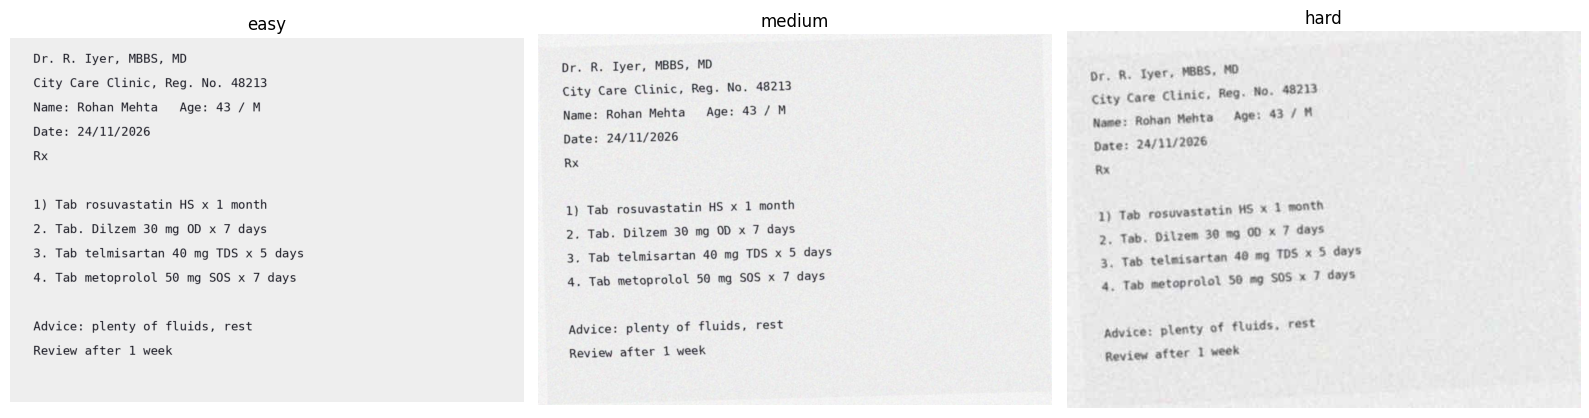

GROUND TRUTH: ['rosuvastatin', 'Dilzem', 'telmisartan', 'metoprolol']

TESSERACT TEXT:
Dr. R. Iyer, MBBS, MD

City Care Clinic, Reg. No. 48213
Name: Rohan Mehta Age: 43 / M
Date: 24/11/2026

Rx

1) Tab rosuvastatin HS x 1 month

2. Tab. Dilzem 30 mg OD x 7 days

3. Tab telmisartan 40 mg TDS x 5 days
4. Tab metoprolol 50 mg SOS x 7 days
Advice: plenty of fluids, rest
Review after 1 week

                                  raw         name strength frequency status              route    ingredients
     1) Tab rosuvastatin HS x 1 month rosuvastatin     None        HS     ok rxnorm:approx_opt1 [rosuvastatin]
     2. Tab. Dilzem 30 mg OD x 7 days       Dilzem    30 mg        OD     ok        brand_table    [diltiazem]
3. Tab telmisartan 40 mg TDS x 5 days  telmisartan    40 mg       TDS     ok rxnorm:approx_opt1  [telmisartan]
 4. Tab metoprolol 50 mg SOS x 7 days   metoprolol    50 mg       SOS     ok rxnorm:approx_opt1   [metoprolol]


In [ ]:
rng = np.random.default_rng(7)
lines, truth = R.make_prescription(pool, rng, n_meds=4)
fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for a, lv in zip(ax, ('easy', 'medium', 'hard')):
    a.imshow(R.render(lines, np.random.default_rng(3), lv)); a.set_title(lv); a.axis('off')
plt.tight_layout(); plt.savefig(WORK + '/fig_08_examples.png', dpi=110); plt.show()
img = R.render(lines, np.random.default_rng(3), 'medium')
txt = R.ocr_tesseract(img)
print('GROUND TRUTH:', [t['name'] for t in truth]); print('\nTESSERACT TEXT:\n' + txt)
meds = R.extract_prescription(txt, resolve)
print(pd.DataFrame(meds)[['raw', 'name', 'strength', 'frequency', 'status', 'route', 'ingredients']].to_string(index=False))
rx_cache.save()

## 2. Benchmark: OCR engines x degradation levels (drug-level precision / recall)

In [ ]:
N = {'tesseract_psm6': 40, 'tesseract_psm4': 40, 'easyocr': 20}
ENGINES = {'tesseract_psm6': lambda im: R.ocr_tesseract(im, 6), 'tesseract_psm4': lambda im: R.ocr_tesseract(im, 4)}
if USE_EASYOCR:
    try:
        R.ocr_easyocr(R.render(['Tab Azithral 500 mg OD'], np.random.default_rng(0), 'easy')); ENGINES['easyocr'] = R.ocr_easyocr
    except Exception as e:
        print('EasyOCR unavailable, skipped:', repr(e)[:150])
rows, store = [], {}
for eng, fn in ENGINES.items():
    for lv in ('easy', 'medium', 'hard'):
        rng = np.random.default_rng(100); preds, truths, texts = [], [], []; t0 = time.time()
        for k in tqdm(range(N[eng]), desc=f'{eng}/{lv}', leave=False):
            ln, tr = R.make_prescription(pool, rng)
            tx = fn(R.render(ln, rng, lv)); texts.append(tx)
            preds.append(R.extract_prescription(tx, resolve)); truths.append(tr)
        sc = R.score_prescriptions(preds, truths)
        rows.append({'engine': eng, 'level': lv, 'n_prescriptions': N[eng], 'sec_per_image': (time.time() - t0) / N[eng], **sc})
        store[(eng, lv)] = (preds, truths, texts)
    rx_cache.save()
res = pd.DataFrame(rows).set_index(['engine', 'level'])
res.to_csv(WORK + '/results_08_ocr.csv')
print(res.round(3).to_string())

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


tesseract_psm6/easy:   0%|          | 0/40 [00:00<?, ?it/s]

tesseract_psm6/medium:   0%|          | 0/40 [00:00<?, ?it/s]

tesseract_psm6/hard:   0%|          | 0/40 [00:00<?, ?it/s]

tesseract_psm4/easy:   0%|          | 0/40 [00:00<?, ?it/s]

tesseract_psm4/medium:   0%|          | 0/40 [00:00<?, ?it/s]

tesseract_psm4/hard:   0%|          | 0/40 [00:00<?, ?it/s]

easyocr/easy:   0%|          | 0/20 [00:00<?, ?it/s]

easyocr/medium:   0%|          | 0/20 [00:00<?, ?it/s]

easyocr/hard:   0%|          | 0/20 [00:00<?, ?it/s]

                       n_prescriptions  sec_per_image  precision  recall     f1   TP  FP  FN  unrecognised_lines
engine         level                                                                                            
tesseract_psm6 easy                 40          1.149        1.0   0.993  0.996  141   0   1                   1
               medium               40          1.332        1.0   0.974  0.987  151   0   4                   3
               hard                 40          1.369        1.0   0.879  0.935  123   0  17                   9
tesseract_psm4 easy                 40          0.969        1.0   0.993  0.996  141   0   1                   1
               medium               40          1.231        1.0   0.974  0.987  151   0   4                   3
               hard                 40          1.254        1.0   0.857  0.923  120   0  20                  10
easyocr        easy                 20         10.820        1.0   0.658  0.793   48   0  25    

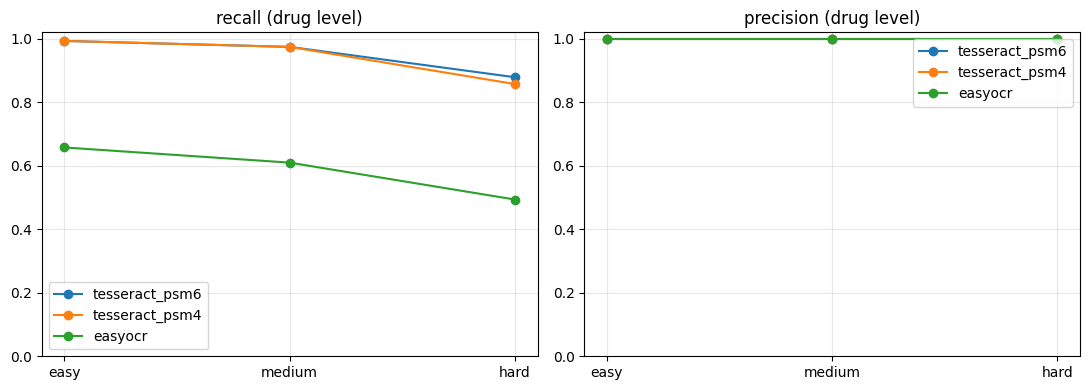

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
piv = res.reset_index()
for a, m in zip(ax, ('recall', 'precision')):
    for eng in piv.engine.unique():
        d = piv[piv.engine == eng]; a.plot(d.level, d[m], marker='o', label=eng)
    a.set_title(m + ' (drug level)'); a.set_ylim(0, 1.02); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(WORK + '/fig_08_ocr_benchmark.png', dpi=110); plt.show()

## 3. Error analysis: where does it fail, and does it ever accept a WRONG drug?
A wrong accepted drug (false positive) is the dangerous error. A missed or unrecognised drug is shown to the user as 'not recognised' and sent to insufficient evidence.

In [ ]:
best = res.loc[(slice(None), 'hard'), 'f1'].idxmax()[0] if len(res) else 'tesseract_psm6'
print('best engine on the hard level (F1):', best)
for lv in ('medium', 'hard'):
    preds, truths, texts = store[(best, lv)]
    fp, miss = [], []
    for meds, tr, tx in zip(preds, truths, texts):
        gt = [frozenset(t['truth']) for t in tr]
        for m in meds:
            s = frozenset(m['ingredients'])
            if m['status'] == 'ok' and m['ingredients'] and s not in gt:
                fp.append((m['raw'][:60], sorted(s), m['route'], m['similarity']))
        got = {frozenset(m['ingredients']) for m in meds if m['status'] == 'ok'}
        miss += [(t['name'], [m['raw'][:50] for m in meds if m['status'] != 'ok'][:2]) for t in tr if frozenset(t['truth']) not in got]
    print(f'\n=== {lv}: {len(fp)} WRONG accepted drugs, {len(miss)} missed drugs')
    for x in fp[:12]: print('  WRONG ', x)
    for x in miss[:10]: print('  missed', x)

best engine on the hard level (F1): tesseract_psm6

=== medium: 0 WRONG accepted drugs, 2 missed drugs
  missed ('HCQS', ['1. Tab Heqs 200 mg 1-0-1 x 5 days'])
  missed ('HCQS', ['3. Tab Heqgs 200 mg OD x 10 days'])

=== hard: 0 WRONG accepted drugs, 15 missed drugs
  missed ('fluconazole', [])
  missed ('Aten', [])
  missed ('Norvasc', ['4) Tab. Norvasc TOS'])
  missed ('hydroxychloroquine', [])
  missed ('Emeset', [])
  missed ('Lexapro', ['3. Tab. Concor § mg 1-0-1 x 5 days', '5. Tab Ditzem 30 mg SOS'])
  missed ('Concor', ['3. Tab. Concor § mg 1-0-1 x 5 days', '5. Tab Ditzem 30 mg SOS'])
  missed ('Dilzem', ['3. Tab. Concor § mg 1-0-1 x 5 days', '5. Tab Ditzem 30 mg SOS'])
  missed ('HCQS', ['1. Tab Heqs 200 mg OD x 10 days'])
  missed ('Clavam', [])


## 4. Save the pipeline choice

In [ ]:
cfg = {'engine': best, 'psm': 4 if best.endswith('psm4') else 6, 'min_similarity': 85, 'brand_fuzzy': 90,
       'results': res.round(4).reset_index().to_dict('records'), 'scope': 'synthetic printed prescriptions only; handwriting not evaluated'}
json.dump(cfg, open(WORK + '/rx_config.json', 'w'), indent=1); print('saved rx_config.json | engine:', best)

saved rx_config.json | engine: tesseract_psm6


## Next
Run notebook 09. Please just tell me *ran fine* plus the results table from section 2 and the WRONG-accepted lists from section 3 (select-and-copy the text), or the error message.